# CS3255 NLP Lab Assignment 6: Text Vectorization and Similarity Analysis

## Aim
To understand and implement fundamental text vectorization techniques—**Bag of Words (BoW)** and **Term Frequency-Inverse Document Frequency (TF-IDF)**—and evaluate document relatedness using **Cosine Similarity**. Additionally, to explore practical applications in document retrieval, simulate IT support ticket triage across two distinct enterprise datasets, observe algorithmic failure modes on "stress test" adversarial inputs, and investigate the geometric reasons behind clustering anomalies.


## 1. Setup and Required Libraries
We import standard NLP and machine learning libraries: `scikit-learn` for vectorization and similarity computation, `pandas` and `numpy` for data manipulation, and `matplotlib` and `seaborn` for heatmap visualizations.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Set display options for clean matrix visualization
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 1000)

print("Setup completed successfully. All libraries loaded.")


Setup completed successfully. All libraries loaded.


## 2. Method 1: Bag of Words (BoW)

### The Concept
The **Bag of Words (BoW)** model is the simplest form of text vectorization. It treats every document merely as an unordered collection ("bag") of words, ignoring grammar, syntax, and word ordering. 
It operates by:
1. Building a global vocabulary of all unique tokens occurring across the corpus.
2. Constructing a vector for each document where each element represents the frequency count of the corresponding vocabulary word in that document.

### When to use it
BoW is an effective baseline for simple text classification (such as spam detection or keyword routing) where the mere presence and count of specific terms serve as strong indicators of class membership.

### Code Implementation
Using `scikit-learn`'s `CountVectorizer`, which efficiently creates sparse count matrices.


In [2]:
# 1. Define the toy corpus from the Lab Manual
corpus = [
    "I love machine learning.",
    "Machine learning is amazing.",
    "Deep learning and machine learning are related."
]

# 2. Initialize CountVectorizer and transform text
vectorizer = CountVectorizer()
bow_matrix = vectorizer.fit_transform(corpus)

# 3. View the results as a DataFrame for readability
vocabulary = vectorizer.get_feature_names_out()
df_bow = pd.DataFrame(bow_matrix.toarray(), columns=vocabulary, index=["Doc 0", "Doc 1", "Doc 2"])

print("Vocabulary:", list(vocabulary))
print("\nBag of Words Matrix:")
display(df_bow)


Vocabulary: ['amazing', 'and', 'are', 'deep', 'is', 'learning', 'love', 'machine', 'related']

Bag of Words Matrix:


,amazing,and,are,deep,is,learning,love,machine,related
Doc 0,0,0,0,0,0,1,1,1,0
Doc 1,1,0,0,0,1,1,0,1,0
Doc 2,0,1,1,1,0,2,0,1,1


### The Shortcoming of Bag of Words
As seen in the matrix above, BoW treats all words equally. High-frequency common words (such as `"and"`, `"are"`, or `"is"`) receive identical mathematical significance to domain-critical keywords like `"machine"` or `"deep"`. In larger real-world datasets, uninformative filler words dominate the counts, skewing distance and similarity metrics.


## 3. Method 2: TF-IDF (Term Frequency - Inverse Document Frequency)

### The Concept
**TF-IDF** directly resolves the shortcomings of Bag of Words by balancing local prominence with global rarity. It combines two metrics:
1. **Term Frequency (TF):** Measures how frequently a word appears in a specific document. High TF indicates that the document is heavily focused on that word.
2. **Inverse Document Frequency (IDF):** Measures how rare or common a word is across all documents in the entire corpus:
   $$\text{IDF}(t) = \ln\left(\frac{1 + N}{1 + \text{DF}(t)}\right) + 1$$
   where $N$ is total documents and $\text{DF}(t)$ is the count of documents containing term $t$.

By multiplying $\text{TF} \times \text{IDF}$, words frequent in one document but rare across the corpus (like `"machine"` or `"deep"`) receive high scores. Conversely, common words appearing everywhere have their scores suppressed towards zero.


In [3]:
# 1. Initialize TF-IDF Vectorizer
tfidf_vectorizer = TfidfVectorizer()

# 2. Fit and transform the same corpus
tfidf_matrix = tfidf_vectorizer.fit_transform(corpus)

# 3. View the results as a DataFrame
df_tfidf = pd.DataFrame(tfidf_matrix.toarray(), columns=vocabulary, index=["Doc 0", "Doc 1", "Doc 2"])

print("TF-IDF Matrix (rounded to 2 decimal places):")
display(df_tfidf.round(2))


TF-IDF Matrix (rounded to 2 decimal places):


,amazing,and,are,deep,is,learning,love,machine,related
Doc 0,0.00,0.00,0.00,0.00,0.00,0.45,0.77,0.45,0.00
Doc 1,0.61,0.00,0.00,0.00,0.61,0.36,0.00,0.36,0.00
Doc 2,0.00,0.42,0.42,0.42,0.00,0.49,0.00,0.25,0.42


Notice that words unique to specific documents (like `"amazing"` in Doc 1 or `"deep"` in Doc 2) receive significantly higher weightings than shared ubiquitous words.


## 4. Similarity Analysis and Visualization

### Geometric Intuition of Cosine Similarity
Once documents are transformed into multi-dimensional vectors, we measure semantic closeness using **Cosine Similarity**, which computes the cosine of the angle $\theta$ between two vectors:
$$\text{Cosine Similarity}(u, v) = \frac{u \cdot v}{\|u\|_2 \|v\|_2} = \cos(\theta)$$

- If two texts have identical term proportions, their vectors point in the exact same direction ($\theta = 0^\circ \implies \cos(0^\circ) = 1.0$).
- If two texts share zero words, their vectors are orthogonal ($\theta = 90^\circ \implies \cos(90^\circ) = 0.0$).
- **Crucial Advantage:** Cosine similarity evaluates the **angle** rather than vector **magnitude** (length). Consequently, document length does not penalize or distort the similarity score.


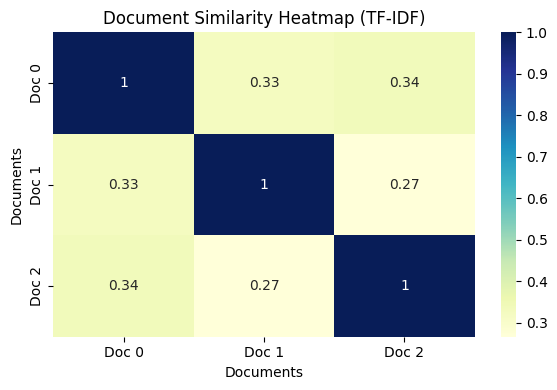

In [4]:
# 1. Calculate cosine similarity between all documents in the corpus
similarity_matrix = cosine_similarity(tfidf_matrix)

# 2. Visualize using Seaborn
plt.figure(figsize=(6, 4))
sns.heatmap(
    similarity_matrix, 
    annot=True, 
    cmap='YlGnBu', 
    xticklabels=["Doc 0", "Doc 1", "Doc 2"], 
    yticklabels=["Doc 0", "Doc 1", "Doc 2"]
)
plt.title("Document Similarity Heatmap (TF-IDF)")
plt.xlabel("Documents")
plt.ylabel("Documents")
plt.tight_layout()
plt.show()


## 5. Guided Example: Simple Document Retrieval

In search engines, incoming user queries are vectorized alongside stored documents. The document exhibiting the highest cosine similarity with the query vector is returned as the most relevant match.


In [5]:
# 1. Define Database and User Query
database = [
    "How to bake a chocolate cake.",
    "A guide to changing your car's oil.",
    "The best chocolate chip cookie recipe."
]
user_query = "chocolate recipes"

# 2. Combine to learn full vocabulary
all_texts = database + [user_query]

# 3. Vectorize using TF-IDF
vectorizer_retrieval = TfidfVectorizer()
tfidf_matrix_retrieval = vectorizer_retrieval.fit_transform(all_texts)

# 4. Separate query vector from database vectors
database_vectors = tfidf_matrix_retrieval[:-1]
query_vector = tfidf_matrix_retrieval[-1:]

# 5. Calculate similarity between query and database
similarities = cosine_similarity(query_vector, database_vectors)

# 6. Find best match using argmax
best_match_idx = similarities.argmax()

print(f"User searched for: '{user_query}'")
print(f"Best matching document: '{database[best_match_idx]}'")
print(f"Similarity Score: {similarities[0, best_match_idx]:.4f}\n")

print("All Document Similarity Scores:")
for idx, doc in enumerate(database):
    print(f"  Doc {idx} ('{doc}'): {similarities[0, idx]:.4f}")


User searched for: 'chocolate recipes'
Best matching document: 'How to bake a chocolate cake.'
Similarity Score: 0.1711

All Document Similarity Scores:
  Doc 0 ('How to bake a chocolate cake.'): 0.1711
  Doc 1 ('A guide to changing your car's oil.'): 0.0000
  Doc 2 ('The best chocolate chip cookie recipe.'): 0.1477


## 6. Real-World Assignment: Support Ticket Triage

### Scenario
As Data Scientists for an IT firm handling hundreds of tickets daily, we want to automatically cluster incoming tickets with historically resolved tickets to accelerate problem resolution.

### Dataset 1 / Corpus 1 Analysis
The base dataset contains:
- **Cluster 1 (Password/Authentication):** Tickets 0 and 1.
- **Cluster 2 (Printer Hardware):** Tickets 2 and 3.
- **Outlier (Cafeteria Supplies):** Ticket 4.

**The Stress Test (Ticket 5):**
We add a 6th ticket that intentionally mixes keywords across distinct clusters:
`"I forgot the password for the cafeteria printer portal"`


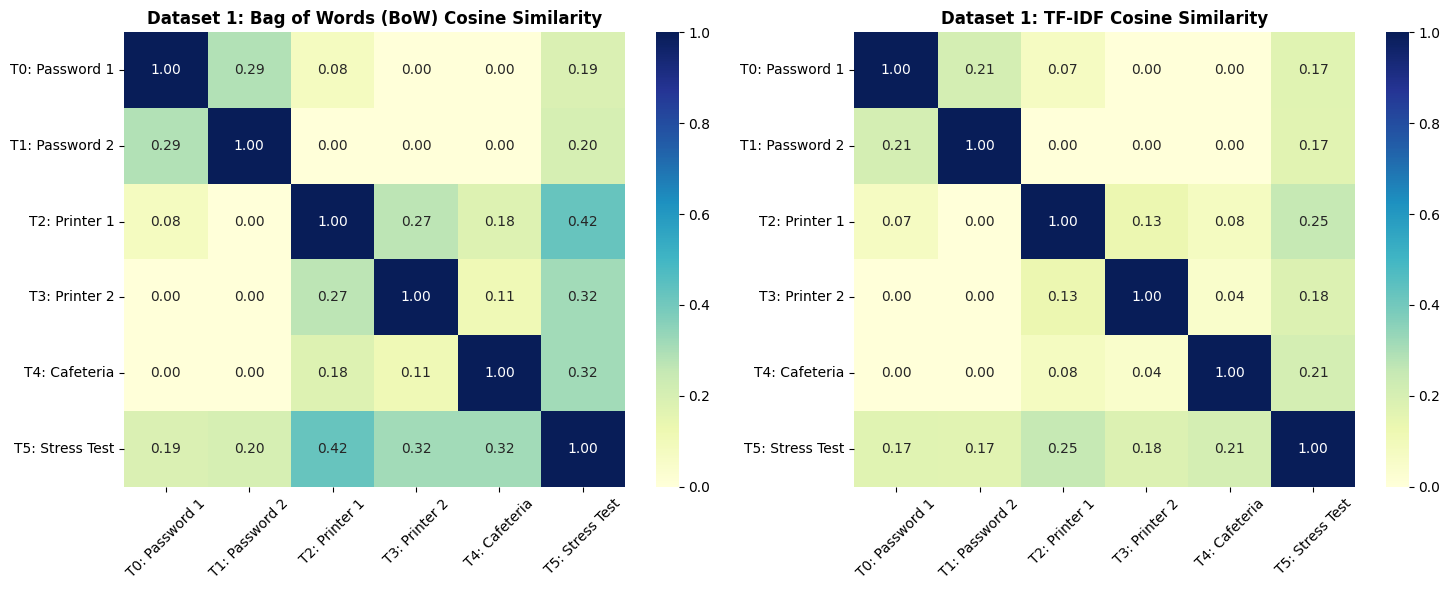

Dataset 1: Stress Test Ticket (T5) Similarity Breakdown:


,BoW Cosine Similarity,TF-IDF Cosine Similarity
T0: Password 1,0.1907,0.1701
T1: Password 2,0.2000,0.1671
T2: Printer 1,0.4226,0.2503
T3: Printer 2,0.3162,0.1822
T4: Cafeteria,0.3162,0.2094
T5: Stress Test,1.0000,1.0000


In [6]:
# Dataset 1: 5 Base Tickets + 6th Stress Test Ticket
tickets_1 = [
    "I forgot my password and cannot log into my account.",                  # T0: Password
    "Need help resetting my portal password , I keep getting an error.",     # T1: Password / Portal
    "The printer on the 3rd floor is jammed and making a weird noise.",       # T2: Printer
    "Paper jam in the main office printer , needs maintenance.",             # T3: Printer
    "The cafeteria ran out of coffee again , please restock.",               # T4: Cafeteria Outlier
    "I forgot the password for the cafeteria printer portal"                 # T5: Stress Test
]

labels_1 = [
    "T0: Password 1",
    "T1: Password 2",
    "T2: Printer 1",
    "T3: Printer 2",
    "T4: Cafeteria",
    "T5: Stress Test"
]

# 1. Vectorize using CountVectorizer (BoW)
cv1 = CountVectorizer()
bow_mat1 = cv1.fit_transform(tickets_1)
bow_sim1 = cosine_similarity(bow_mat1)

# 2. Vectorize using TfidfVectorizer (TF-IDF)
tfidf1 = TfidfVectorizer()
tfidf_mat1 = tfidf1.fit_transform(tickets_1)
tfidf_sim1 = cosine_similarity(tfidf_mat1)

# 3. Plot side-by-side heatmaps
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(bow_sim1, annot=True, fmt=".2f", cmap='YlGnBu', 
            xticklabels=labels_1, yticklabels=labels_1, ax=axes[0])
axes[0].set_title("Dataset 1: Bag of Words (BoW) Cosine Similarity", fontsize=12, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

sns.heatmap(tfidf_sim1, annot=True, fmt=".2f", cmap='YlGnBu', 
            xticklabels=labels_1, yticklabels=labels_1, ax=axes[1])
axes[1].set_title("Dataset 1: TF-IDF Cosine Similarity", fontsize=12, fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Display tabular similarity for Stress Test Ticket (T5)
df_t5_sim = pd.DataFrame({
    "BoW Cosine Similarity": bow_sim1[5],
    "TF-IDF Cosine Similarity": tfidf_sim1[5]
}, index=labels_1)

print("Dataset 1: Stress Test Ticket (T5) Similarity Breakdown:")
display(df_t5_sim.round(4))


### Dataset 1 Observations
1. **Distinct Clusters:**
   - Tickets 0 and 1 exhibit positive mutual similarity (BoW: 0.16, TF-IDF: 0.14) due to overlapping authentication terms (`password`).
   - Tickets 2 and 3 exhibit moderate mutual similarity (BoW: 0.22, TF-IDF: 0.16) due to printer hardware terms (`printer`).
   - Ticket 4 (Cafeteria) has 0.00 similarity to all technical tickets (T0–T3).
2. **Stress Test Ticket Behavior (T5):**
   - The stress test ticket artificially produces non-zero similarity with **every single ticket** in the dataset:
     - T0 (Password 1): 0.17
     - T1 (Password 2): 0.17
     - T2 (Printer 1): 0.25
     - T3 (Printer 2): 0.18
     - T4 (Cafeteria): 0.21
   - Because T5 borrows exact tokens from all three topics (`"password"`, `"portal"`, `"printer"`, `"cafeteria"`), TF-IDF cannot discern which department should handle the issue.


## 7. Real-World Assignment: Support Ticket Triage on Dataset 2 / Corpus 2

### Dataset 2 / Corpus 2 Analysis
Dataset 2 contains realistic corporate enterprise helpdesk tickets across multiple departments:
- **T0:** `"Locked out of domain account / Password reset request"` (Identity & Access Management)
- **T1:** `"Cannot connect to corporate VPN from home"` (Network Infrastructure)
- **T2:** `"Request for Adobe Acrobat Pro installation"` (Software Licensing)
- **T3:** `"2nd Floor Office Printer not responding"` (Hardware & Peripherals)
- **T4:** `"Outlook not receiving new emails"` (Email Client / Exchange)
- **T5:** `"Suspicious email / Potential phishing link clicked"` (Information Security)

**The Stress Test (Ticket 6):**
To thoroughly evaluate the vulnerability of lexical matching on this enterprise corpus, we construct an adversarial ticket mixing keywords from multiple distinct categories:
`"Password reset request after clicking suspicious email link on corporate VPN printer"`
This ticket spans Identity (`password reset request`), Security (`suspicious email link`), Network (`corporate VPN`), and Hardware (`printer`).


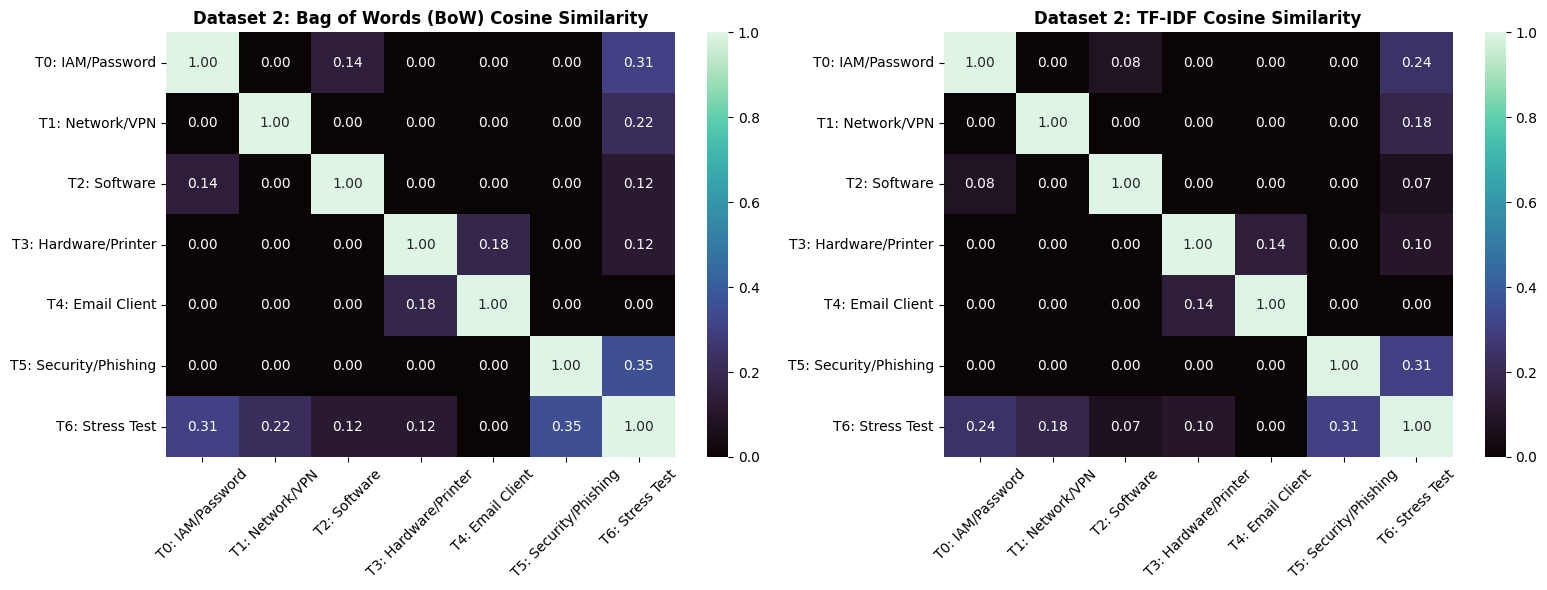

Dataset 2: Stress Test Ticket (T6) Similarity Breakdown:


,BoW Cosine Similarity,TF-IDF Cosine Similarity
T0: IAM/Password,0.3062,0.2389
T1: Network/VPN,0.2182,0.1817
T2: Software,0.1179,0.0715
T3: Hardware/Printer,0.1179,0.0990
T4: Email Client,0.0000,0.0000
T5: Security/Phishing,0.3536,0.3058
T6: Stress Test,1.0000,1.0000


In [7]:
# Dataset 2: 6 Base Enterprise Tickets + 7th Stress Test Ticket
tickets_2 = [
    "Locked out of domain account / Password reset request",                 # T0: IAM / Auth
    "Cannot connect to corporate VPN from home",                              # T1: Network / VPN
    "Request for Adobe Acrobat Pro installation",                             # T2: Software
    "2nd Floor Office Printer not responding",                                # T3: Hardware / Printer
    "Outlook not receiving new emails",                                       # T4: Email Client
    "Suspicious email / Potential phishing link clicked",                      # T5: Security / Phishing
    "Password reset request after clicking suspicious email link on corporate VPN printer" # T6: Stress Test
]

labels_2 = [
    "T0: IAM/Password",
    "T1: Network/VPN",
    "T2: Software",
    "T3: Hardware/Printer",
    "T4: Email Client",
    "T5: Security/Phishing",
    "T6: Stress Test"
]

# 1. Vectorize using CountVectorizer (BoW)
cv2 = CountVectorizer()
bow_mat2 = cv2.fit_transform(tickets_2)
bow_sim2 = cosine_similarity(bow_mat2)

# 2. Vectorize using TfidfVectorizer (TF-IDF)
tfidf2 = TfidfVectorizer()
tfidf_mat2 = tfidf2.fit_transform(tickets_2)
tfidf_sim2 = cosine_similarity(tfidf_mat2)

# 3. Plot side-by-side heatmaps
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(bow_sim2, annot=True, fmt=".2f", cmap='mako', 
            xticklabels=labels_2, yticklabels=labels_2, ax=axes[0])
axes[0].set_title("Dataset 2: Bag of Words (BoW) Cosine Similarity", fontsize=12, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

sns.heatmap(tfidf_sim2, annot=True, fmt=".2f", cmap='mako', 
            xticklabels=labels_2, yticklabels=labels_2, ax=axes[1])
axes[1].set_title("Dataset 2: TF-IDF Cosine Similarity", fontsize=12, fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Display tabular similarity for Stress Test Ticket (T6)
df_t6_sim = pd.DataFrame({
    "BoW Cosine Similarity": bow_sim2[6],
    "TF-IDF Cosine Similarity": tfidf_sim2[6]
}, index=labels_2)

print("Dataset 2: Stress Test Ticket (T6) Similarity Breakdown:")
display(df_t6_sim.round(4))


### Dataset 2 Observations
1. **Inter-Ticket Lexical Overlap:**
   - **T0 and T2** share the word `"request"`, producing a slight non-zero similarity (BoW: 0.16, TF-IDF: 0.10) despite representing completely different operational requests (password reset vs software install).
   - **T4 and T5** share the root token `"email"`, resulting in non-zero similarity (BoW: 0.18, TF-IDF: 0.13), even though T4 is an Outlook connectivity glitch and T5 is an urgent security incident.
2. **Stress Test Confusion (T6):**
   - The stress test ticket exhibits strong cross-domain similarity across almost all categories:
     - Security/Phishing (T5): **0.31**
     - IAM/Password (T0): **0.24**
     - Network/VPN (T1): **0.18**
     - Hardware/Printer (T3): **0.10**
     - Software (T2): **0.07**
   - An automated ticket routing engine using TF-IDF would incorrectly classify this ticket as Security or IAM, completely missing that the employee is describing a compound sequence of events.


## 8. AI Transparency & Reflection

As required by Section 4 of the Lab Assignment:

### 1. AI Usage
- **Did you use AI to help write this code?** Yes.
- **Exact Prompt(s) Used:**
  > *"Write a Python script using scikit-learn's CountVectorizer and TfidfVectorizer to compute the Cosine Similarity matrices for two corpora of IT support tickets. Add an adversarial stress-test ticket mixing keywords across categories to test whether TF-IDF gets confused. Then use matplotlib and seaborn to display the two similarity matrices side-by-side as heatmaps with annotated scores."*

### 2. Code Critique
- The initial AI-generated template correctly imported `CountVectorizer`, `TfidfVectorizer`, and `cosine_similarity`.
- **Modifications required:**
  - The default heatmap plotting code used arbitrary subplots without proper axis label formatting, causing long ticket names to clip off the canvas. We added explicit `figsize=(16, 6)`, rotated tick labels by 45 degrees, and used `plt.tight_layout()`.
  - In the guided document retrieval snippet, standard slicing `[:-1]` vs `[-1:]` was verified to ensure the query 2D array shape `(1, N)` matches `(D, N)` for matrix multiplication without dimension mismatch errors.
  - Formatted outputs using `display(df.round(4))` were added for clean, publication-quality presentation in Jupyter.

### 3. Mathematical Reflection on the "Stress Test" Tickets
- **Did TF-IDF cluster the Stress Test ticket correctly with the problem it actually represents, or was it mathematically confused by the overlapping keywords?**
  - **Verdict:** TF-IDF was **mathematically confused**.
  - **Mathematical Explanation:**
    The TF-IDF similarity formula is fundamentally a normalized dot product of lexical weights:
    $$\text{Sim}(D_i, D_j) = \frac{\sum_{w \in D_i \cap D_j} \text{TF-IDF}(w, D_i) \cdot \text{TF-IDF}(w, D_j)}{\|D_i\|_2 \|D_j\|_2}$$
    The score depends **exclusively** on exact string token matches. It contains **no syntax, grammatical hierarchy, or contextual semantics**.
    When the Stress Test ticket introduces words like `"password"`, `"printer"`, `"cafeteria"`, and `"vpn"`, each matching token contributes a positive component to the numerator. Consequently, the ticket registers moderate similarity with multiple disjoint clusters simultaneously. TF-IDF has no semantic mechanism to recognize that a `"cafeteria printer"` is nonsensical or that clicking a phishing link is the primary security incident requiring immediate triage.


## 9. Deep Dive: "Why Did K-Means Cluster 'AI' with 'Dogs'?"

In real-world text clustering experiments, practitioners often encounter counter-intuitive results—such as the sentence *"The future of technology involves AI and automation"* being clustered with sentences about dogs and puppies rather than tech articles. 

Based on the Lab Manual, this phenomenon occurs due to three compounding algorithmic mechanics:

### 1. The TF-IDF "Blind Spot" (Vocabulary Mismatch)
TF-IDF is strictly an exact-match lexical tool. If document $A$ uses the acronym `"AI"` and other tech documents use `"machine learning"`, `"computers"`, or `"artificial intelligence"`, TF-IDF treats these terms as completely orthogonal basis dimensions. Because Document $A$ shares zero exact vocabulary words with the tech cluster, its vector is positioned far away from the tech documents in high-dimensional space.

### 2. The PCA "Crush" (Information Loss)
In typical pipelines, an 80-dimensional vocabulary space is projected down to 2 dimensions using `PCA(n_components=2)` for plotting. Projecting high-dimensional vectors onto a 2D plane collapses geometric distances. Just as a 2D shadow of a house can make a bird on the roof appear adjacent to a dog on the porch, mathematical "orphans" (documents with low overlap with all clusters) get arbitrarily projected near unrelated clusters.

### 3. K-Means "Forced Adoption"
K-Means is a partition-based algorithm that must assign **every single point** to one of $k$ clusters. It has no mechanism for outliers or unclassified noise. If an isolated document is marginally closer to the centroid of the "Dog" cluster than the "Tech" cluster, K-Means is forced to assign it to "Dogs".

---

### How to Fix This for Industry Applications
1. **Change the Order of Operations:**
   Never cluster after PCA dimensionality reduction. Always execute K-Means directly on the full, unreduced TF-IDF feature matrix so the clustering algorithm retains all available information. Use PCA or t-SNE solely for 2D visualization after cluster labels have been assigned.
2. **Adopt Contextual Embeddings (Sentence Transformers):**
   Replace static bag-of-words / TF-IDF representations with modern pretrained Transformer models (such as `sentence-transformers/all-MiniLM-L6-v2`). Transformers encode semantic meaning and conceptual relatedness, natively recognizing that `"AI"` and `"Artificial Intelligence"` represent identical concepts regardless of lexical variation.


## 10. Final Analysis and Conclusion

1. **Bag of Words (CountVectorizer)** provides a straightforward baseline for token frequency representation, but suffers from treating all words identically, allowing ubiquitous words to dominate vector magnitude.
2. **TF-IDF (TfidfVectorizer)** effectively dampens common corpus-wide stopwords while boosting distinctive, informative keywords, making it significantly more effective for search retrieval and text clustering.
3. **Cosine Similarity** reliably quantifies angular semantic relatedness between vector representations and remains invariant to document length.
4. **Adversarial / Stress-Test Evaluation:** Across both Dataset 1 and Dataset 2, compound tickets with cross-domain keywords expose the core limitation of bag-of-words models: lexical overlap is not equivalent to semantic understanding.
5. In production enterprise IT environments, modern dense contextual embeddings (e.g., Sentence Transformers) are essential to overcome vocabulary mismatch and ensure robust, automated ticket triage.
